# MGSC 672: Operations & Supply Chain 
## <font color=#FF0000>Case 1: Fashion: Art vs. Science Analysis</font>


This notebook contains all code and associated work for Group 4. 

| Student ID | Student name   | Student email                  |
| ---------- | -------------- | ------------------------------ |
| 261087292  | Luice Peccoux  | lucie.peccoux@mail.mcgill.ca   |
| 261077392  | Julie Chanzy   | julie.chanzy@mail.mcgill.ca    |
| 261076605  | Priyanka Jahul | chhaya.jahul@mail.mcgill.ca    |
| 260658030  | Emery Dittmer  | emery.dittmer@mail.mcgill.ca   |
| 261102578  | Sunny Wu       | zhenye.wu@mail.mcgill.ca       |
| 261060598  | Michael Murphy | michael.murphy6@mail.mcgill.ca |

## 1. Data Pre-Processing

### 1.1 Load Data into Model

In [63]:
#import libraries
import pandas as pd

#plotting software
import seaborn as sns
import plotly.express as px
from matplotlib import pyplot
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import r2_score

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.linear_model import Lasso


import statsmodels.api as sm



In [2]:
df=pd.read_excel("Flashion Art vs Science in Fashion Retailing_621712-XLS-ENG.xlsx",sheet_name="data")

In [3]:
df.head(4)

,Style#,Event#,Starting Inventory,Quantity Sold,Cost,Price,MSRP,Department,Month,Event Start Time,Event Start DOW,Shipping Method
0,23454,284,115,77,7,9.99,39,Footwear,Oct,10:00:00,Monday,F
1,25783,304,126,91,7,9.99,29,Footwear,Oct,10:00:00,Thursday,F
2,2990,314,92,78,7,9.99,39,Footwear,Oct,10:00:00,Thursday,F
3,21412,289,115,115,7,9.99,27,Footwear,Oct,10:00:00,Wednesday,F


### 1.2 Cleaning Data

In [4]:
#checking null values
df.isnull().values.any()

False

In [5]:
#copy of dataframe for backup
f=df.copy()

## 2. Basic Data Invetigation

### 2.1 Prelime data investigation 
investigating corelation plots, column names, basic dataframe values

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30389 entries, 0 to 30388
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Style#              30389 non-null  int64  
 1   Event#              30389 non-null  int64  
 2   Starting Inventory  30389 non-null  int64  
 3   Quantity Sold       30389 non-null  int64  
 4   Cost                30389 non-null  int64  
 5   Price               30389 non-null  float64
 6   MSRP                30389 non-null  int64  
 7   Department          30389 non-null  object 
 8   Month               30389 non-null  object 
 9   Event Start Time    30389 non-null  object 
 10  Event Start DOW     30389 non-null  object 
 11  Shipping Method     30389 non-null  object 
dtypes: float64(1), int64(6), object(5)
memory usage: 2.8+ MB


In [7]:
df.columns

Index(['Style#', 'Event#', 'Starting Inventory', 'Quantity Sold', 'Cost',
       'Price', 'MSRP', 'Department', 'Month', 'Event Start Time',
       'Event Start DOW', 'Shipping Method'],
      dtype='object')

In [8]:
df.describe()

,Style#,Event#,Starting Inventory,Quantity Sold,Cost,Price,MSRP
count,30389.000000,30389.000000,30389.000000,30389.000000,30389.000000,30389.000000,30389.000000
mean,15195.000000,501.853138,47.691303,30.787259,216.413176,281.896775,424.815032
std,8772.693002,288.226333,29.233302,23.812049,190.240776,247.573706,310.686540
min,1.000000,1.000000,1.000000,0.000000,5.000000,9.990000,25.000000
25%,7598.000000,251.000000,23.000000,13.000000,80.000000,104.990000,174.000000
50%,15195.000000,505.000000,45.000000,26.000000,150.000000,194.990000,336.000000
75%,22792.000000,749.000000,69.000000,43.000000,303.000000,394.990000,593.000000
max,30389.000000,1000.000000,167.000000,161.000000,1304.000000,1754.990000,2160.000000


### 2.2 Investigation of Day of the week effect

<b> Mondays </b>

In [32]:
f1 = f[f['Event Start DOW'] == 'Monday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
mon_sell_thr = perc_inv_sold.mean()
print(perc_inv_sold)
print("=> Average sell-through: ", mon_sell_thr)

Event#
1      62.573443
2      68.944099
6      75.394548
10     54.336918
14     44.262295
         ...    
984    63.168317
987    67.649123
992    65.714286
994    53.521127
999    51.124903
Length: 177, dtype: float64
=> Average sell-through:  65.02903645035323


In [33]:
sell_through_dict = {}
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Tuesdays </b>

In [34]:
f1 = f[f['Event Start DOW'] == 'Tuesday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
tues_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", tues_sell_thr)

=> Average sell-through:  64.34697388551513


In [35]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Wednesdays </b>

In [36]:
f1 = f[f['Event Start DOW'] == 'Wednesday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
wed_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", wed_sell_thr)

=> Average sell-through:  65.04219056799147


In [37]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Thursdays </b>

In [38]:
f1 = f[f['Event Start DOW'] == 'Thursday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
thurs_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", thurs_sell_thr)

=> Average sell-through:  64.43098434927371


In [39]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Fridays </b>

In [40]:
f1 = f[f['Event Start DOW'] == 'Friday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
fri_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", fri_sell_thr)

=> Average sell-through:  65.27174685965396


In [41]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Saturdays </b>

In [42]:
f1 = f[f['Event Start DOW'] == 'Saturday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
sat_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", sat_sell_thr)

=> Average sell-through:  61.28447173108234


In [43]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

<b> Sundays </b>

In [44]:
f1 = f[f['Event Start DOW'] == 'Sunday']
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
sun_sell_thr = perc_inv_sold.mean()
#print(perc_inv_sold)
print("=> Average sell-through: ", sun_sell_thr)

=> Average sell-through:  61.319407178743276


In [45]:
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc

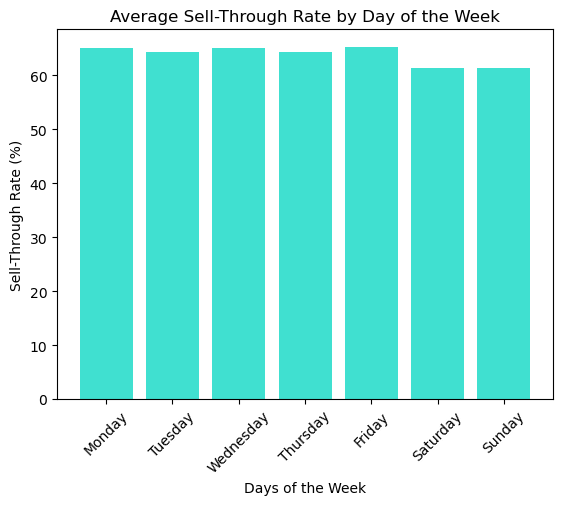

In [95]:
# Average sell-through rates for each day of the week
sell_thr_rates = [mon_sell_thr, tues_sell_thr, wed_sell_thr, thurs_sell_thr, fri_sell_thr, sat_sell_thr, sun_sell_thr]

# Days of the week
days_of_week = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Plotting the bar chart
bar_color = 'turquoise'
plt.bar(days_of_week, sell_thr_rates, color = bar_color)

# Adding labels and title
plt.xlabel('Days of the Week')
plt.ylabel('Sell-Through Rate (%)')
plt.title('Average Sell-Through Rate by Day of the Week')

# Rotating x-axis labels for better readability
plt.xticks(rotation=45)

# Display the plot
plt.show()

Conclusion: weekday is not a significant contributor in predictions

### 2.3 Investigation of Month Effect

In [49]:
#data transformations
for event_num, sell_through_perc in zip(event_sales.index, perc_inv_sold):
    sell_through_dict[event_num] = sell_through_perc
f['sell_through'] = f['Event#'].map(sell_through_dict)
f['discount'] = 100*(f['MSRP']-f['Price'])/f['MSRP']

<b> October </b>

In [50]:
f1 = f[(f['Month'] == 'Oct')]
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
oct_sell_thr_avg = perc_inv_sold.mean()
print(perc_inv_sold)
print("=> October average sell-through: ", oct_sell_thr_avg)

Event#
1      62.573443
2      68.944099
4      37.952430
14     44.262295
15     78.208441
         ...    
729    54.140491
740    59.800000
741    66.970091
742    63.149728
745    85.444532
Length: 306, dtype: float64
=> October average sell-through:  65.87616892267793


<b> November </b>

In [51]:
f1 = f[(f['Month'] == 'Nov')]
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
nov_sell_thr_avg = perc_inv_sold.mean()
print(perc_inv_sold)
print("=> November average sell-through: ", nov_sell_thr_avg)

Event#
5       78.345662
7       60.978261
9       38.544892
10      54.336918
12      58.294157
          ...    
994     53.521127
995     67.483189
997     72.514205
999     51.124903
1000    69.679715
Length: 297, dtype: float64
=> November average sell-through:  67.30097523731067


<b> December </b>

In [52]:
f1 = f[(f['Month'] == 'Dec')]
event_sales = f1.groupby('Event#')['Quantity Sold'].sum()
event_inv = f1.groupby('Event#')['Starting Inventory'].sum()
perc_inv_sold = (event_sales/event_inv)*100
dec_sell_thr_avg = perc_inv_sold.mean()
print(perc_inv_sold)
print("=> December average sell-through: ", dec_sell_thr_avg)

Event#
3      52.759588
6      75.394548
8      67.796610
11     83.922559
13     60.591527
         ...    
989    57.619048
992    65.714286
993    62.560680
996    69.510665
998    76.321138
Length: 397, dtype: float64
=> December average sell-through:  60.50062907360021


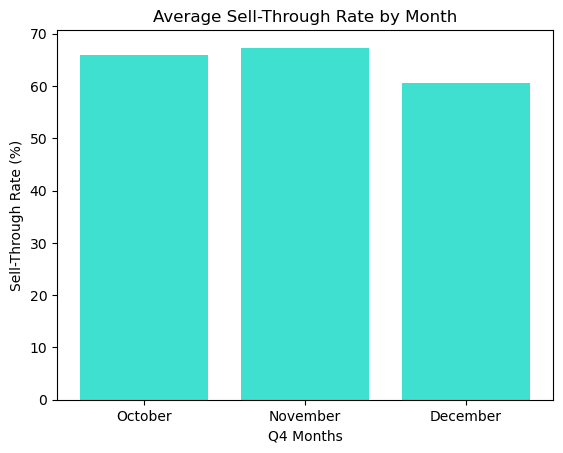

In [53]:
# Average sell-through rates per month
month_sell_thr_rates = [oct_sell_thr_avg, nov_sell_thr_avg, dec_sell_thr_avg]

# Days of the week
months = ['October', 'November', 'December']

# Plotting the bar chart
bar_color = 'turquoise'
plt.bar(months, month_sell_thr_rates, color = bar_color)

# Adding labels and title
plt.xlabel('Q4 Months')
plt.ylabel('Sell-Through Rate (%)')
plt.title('Average Sell-Through Rate by Month')

# Display the plot
plt.show()

Conclusion: No significant difference between months

## 2.4 Corlation Plots and relationships

### 2.4.1 Basic Correlations

In [54]:
df.corr()

C:\Users\raymo\AppData\Local\Temp\ipykernel_23740\1134722465.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  df.corr()


,Style#,Event#,Starting Inventory,Quantity Sold,Cost,Price,MSRP
Style#,1.000000,0.001733,-0.003679,-0.005761,-0.003618,-0.003275,-0.003207
Event#,0.001733,1.000000,0.047687,0.047182,0.039151,0.038597,0.052225
Starting Inventory,-0.003679,0.047687,1.000000,0.658393,-0.187945,-0.188548,-0.116870
Quantity Sold,-0.005761,0.047182,0.658393,1.000000,-0.310033,-0.310726,-0.213493
Cost,-0.003618,0.039151,-0.187945,-0.310033,1.000000,0.999354,0.957256
Price,-0.003275,0.038597,-0.188548,-0.310726,0.999354,1.000000,0.957394
MSRP,-0.003207,0.052225,-0.116870,-0.213493,0.957256,0.957394,1.000000


C:\Users\raymo\AppData\Local\Temp\ipykernel_23740\1227362056.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  corr = df.corr()


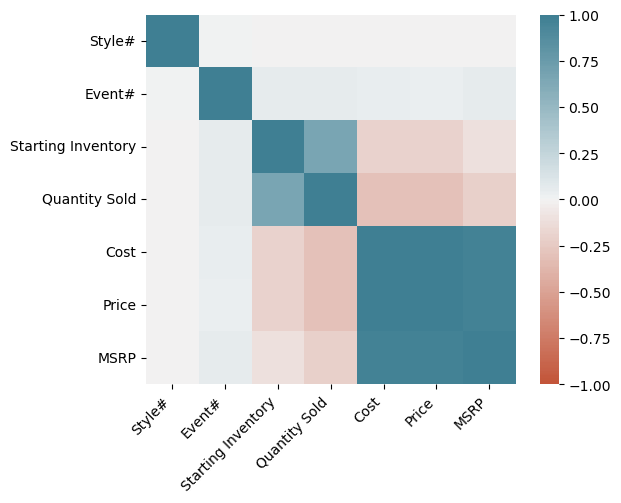

In [55]:
corr = df.corr()
ax = sns.heatmap(
    corr, 
    vmin=-1, vmax=1, center=0,
    cmap=sns.diverging_palette(20, 220, n=200),
    square=True
)
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    horizontalalignment='right'
);

### 2.4.2 Correlation plot with discount and non-unique fields

C:\Users\raymo\AppData\Local\Temp\ipykernel_23740\1249377994.py:8: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation_table = selected_data.corr()


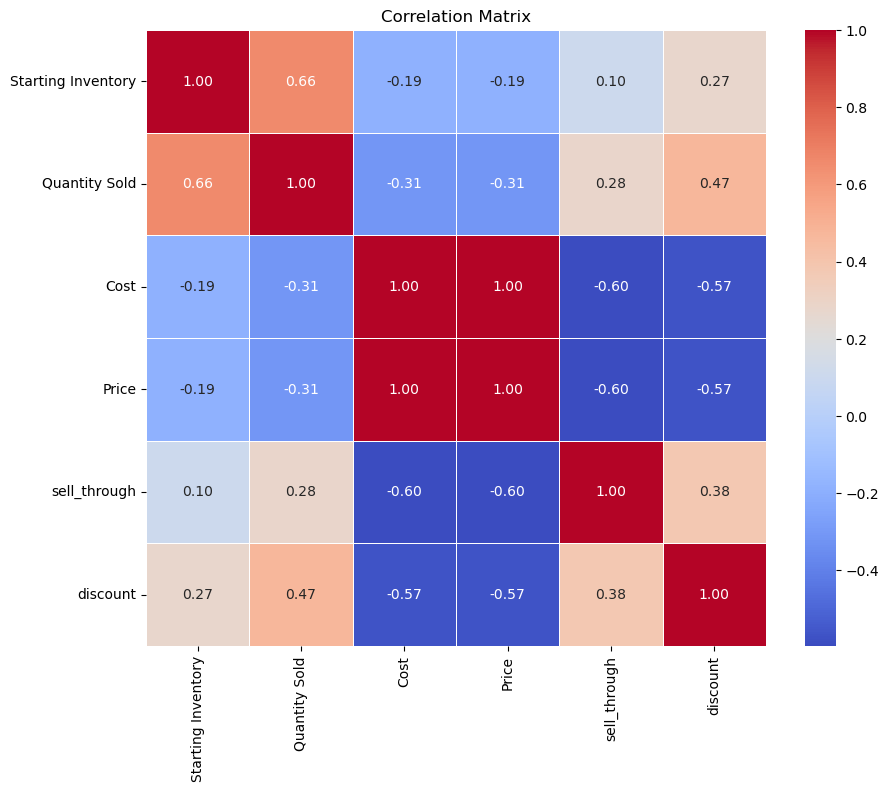

In [56]:
# Select the columns for correlation analysis
selected_columns = ['Starting Inventory', 'Quantity Sold', 'Cost', 'Price', 'Department', 'Month', 'Event Start DOW', 'Shipping Method', 'sell_through', 'discount']

# Subset the data with the selected columns
selected_data = f[selected_columns]

# Calculate the correlation matrix
correlation_table = selected_data.corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_table, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


### 2.4.3 Advanced Correlation Plot

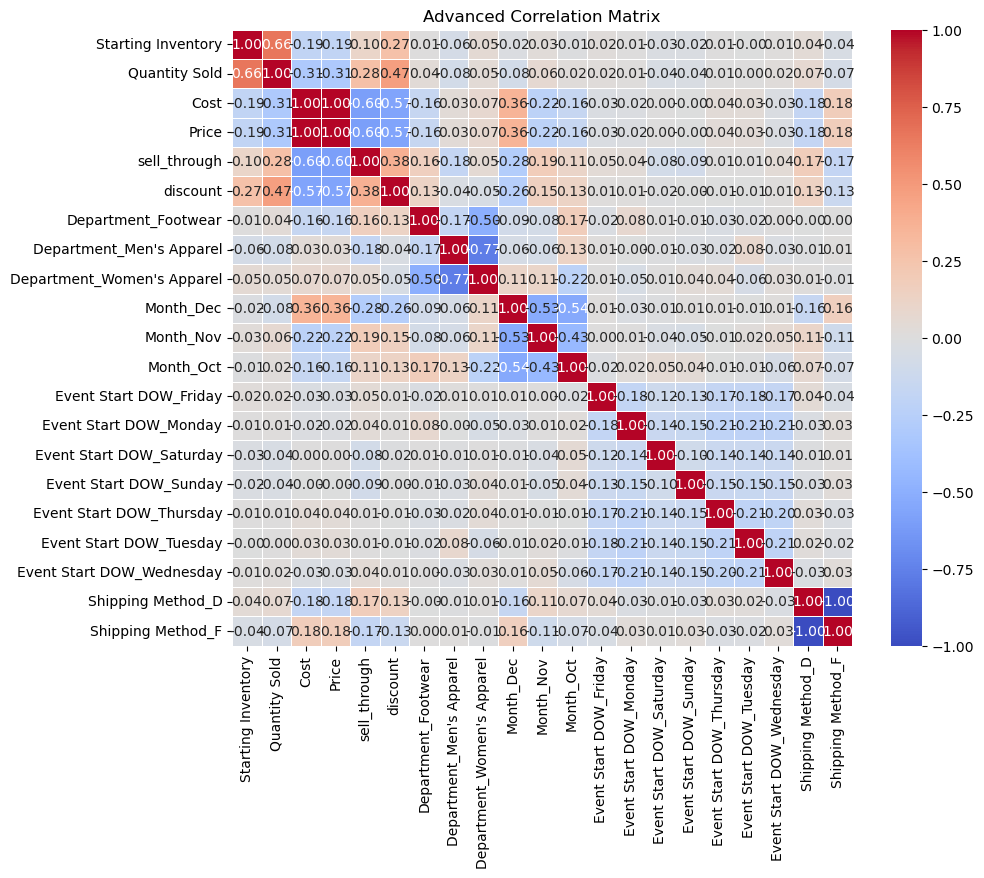

In [57]:
# Dummify the string variables
string_columns = selected_data.select_dtypes(include='object').columns
dummified_data = pd.get_dummies(selected_data, columns=string_columns)
# Calculate the correlation matrix
correlation_table_adv = dummified_data.corr()

# Create a heatmap of the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_table_adv, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Advanced Correlation Matrix')
plt.show()

## 2.5 Other Data investigation

### 2.5.1 exponential decay of revenue (parateo principle)

In [58]:
df2 = df.groupby('Style#').agg({'Quantity Sold': ['sum','count'],'Price':['mean']})
df2['revenue']=df2['Quantity Sold']['sum']*df2['Price']['mean']
df2['Style#'] = df2.index.astype(str)
df2.sort_values('revenue', axis=0, ascending=False, inplace=True) 
df2.head()

Quantity Sold          Price   revenue Style#
                 sum count     mean                 
Style#                                              
6558             101     1   949.99  95948.99   6558
14769             84     1  1074.99  90299.16  14769
3729              84     1   989.99  83159.16   3729
7991              99     1   834.99  82664.01   7991
17629             72     1  1134.99  81719.28  17629

In [59]:
df3=df2.head(1000)
fig = px.bar(df3, x='Style#', y='revenue',color='revenue')
fig.show()

In [86]:
#df4 = df.groupby(['Style#','Department']).agg({'Quantity Sold': ['sum','count'],'Price':['mean']})
df4=df.copy()
#df4['revenue']=df4['Quantity Sold']['sum']*df4['Price']['mean']
df4['revenue']=df4['Quantity Sold']*df4['Price']
df4['revenue_percentile'] = df4['revenue'].rank(pct=True)

# Determine thresholds for label categories
top_20_threshold = df4['revenue_percentile'].quantile(0.8)
next_40_threshold = df4['revenue_percentile'].quantile(0.4)

# Assign labels based on thresholds
df4['label'] = 'C'  # Default label for all items
df4.loc[df4['revenue_percentile'] > next_40_threshold, 'label'] = 'B'
df4.loc[df4['revenue_percentile'] > top_20_threshold, 'label'] = 'A'
df4.reset_index(inplace=True)  

df4=df4[["label", "Department", "revenue"]]

df4=df4.groupby(['label','Department']).agg({'revenue': ['sum']})
df4.reset_index(inplace=True)
df4

,label,Department,revenue
,,,sum
0,A,Footwear,5562227.84
1,A,Men's Apparel,18042979.36
2,A,Women's Apparel,92819988.79
3,B,Footwear,5842944.88
4,B,Men's Apparel,15441619.36
5,B,Women's Apparel,53076759.90
6,C,Footwear,2010782.85
7,C,Men's Apparel,3599022.09
8,C,Women's Apparel,11679698.99


In [97]:
data = {
    'label': ['A', 'A', 'A', 'B', 'B', 'B', 'C', 'C', 'C'],
    'Department': ['Footwear', "Men's Apparel", "Women's Apparel", 'Footwear', "Men's Apparel", "Women's Apparel", 'Footwear', "Men's Apparel", "Women's Apparel"],
    'revenue': [5562227.84, 18042979.36, 92819988.79, 5842944.88, 15441619.36, 53076759.90, 2010782.85, 3599022.09, 11679698.99]
}

df_temp = pd.DataFrame(data)

In [98]:
fig = px.bar(df_temp, x='label', y='revenue', color="Department")
fig.show()

In [100]:
# Calculate the total revenue for each label
total_revenue = df_temp.groupby('label')['revenue'].transform('sum')

# Calculate the revenue percentage for each row
df_temp['revenue_percentage'] = df_temp['revenue'] / total_revenue * 100

# Plot the modified DataFrame
fig = px.bar(df_temp, x='label', y='revenue_percentage', color='Department', title='Revenue Percentage by Label')
fig.show()

## 3. Data Transformations & Feature engineering

## Transformations

In [58]:
df_dummies = pd.get_dummies(data=df)
df_dummies["rank in event by price"] = df_dummies.groupby("Event#")["Price"].rank(method="dense", ascending=True)
df_dummies.head()

,Style#,Event#,Starting Inventory,Quantity Sold,Cost,Price,MSRP,Department_Footwear,Department_Men's Apparel,Department_Women's Apparel,...,Event Start DOW_Friday,Event Start DOW_Monday,Event Start DOW_Saturday,Event Start DOW_Sunday,Event Start DOW_Thursday,Event Start DOW_Tuesday,Event Start DOW_Wednesday,Shipping Method_D,Shipping Method_F,rank in event by price
0,23454,284,115,77,7,9.99,39,1,0,0,...,0,1,0,0,0,0,0,0,1,1.0
1,25783,304,126,91,7,9.99,29,1,0,0,...,0,0,0,0,1,0,0,0,1,1.0
2,2990,314,92,78,7,9.99,39,1,0,0,...,0,0,0,0,1,0,0,0,1,1.0
3,21412,289,115,115,7,9.99,27,1,0,0,...,0,0,0,0,0,0,1,0,1,1.0
4,8211,284,133,133,7,9.99,41,1,0,0,...,0,1,0,0,0,0,0,0,1,1.0


In [65]:
y=df_dummies['Quantity Sold']
X=df_dummies.drop(columns=['Quantity Sold'])

In [66]:
X=X.drop(columns=['Style#','Cost','Event#','Shipping Method_D','Shipping Method_F'])

In [67]:
X.head()

,Starting Inventory,Price,MSRP,Department_Footwear,Department_Men's Apparel,Department_Women's Apparel,Month_Dec,Month_Nov,Month_Oct,Event Start Time_10:00:00,...,Event Start DOW_Friday,Event Start DOW_Monday,Event Start DOW_Saturday,Event Start DOW_Sunday,Event Start DOW_Thursday,Event Start DOW_Tuesday,Event Start DOW_Wednesday,Shipping Method_D,Shipping Method_F,rank in event by price
0,115,9.99,39,1,0,0,0,0,1,1,...,0,1,0,0,0,0,0,0,1,1.0
1,126,9.99,29,1,0,0,0,0,1,1,...,0,0,0,0,1,0,0,0,1,1.0
2,92,9.99,39,1,0,0,0,0,1,1,...,0,0,0,0,1,0,0,0,1,1.0
3,115,9.99,27,1,0,0,0,0,1,1,...,0,0,0,0,0,0,1,0,1,1.0
4,133,9.99,41,1,0,0,0,0,1,1,...,0,1,0,0,0,0,0,0,1,1.0


## 4. Predictions & Modeling

### 4.1 Feature importance

### 4.1.1 Feautre importance with Linear regression all Variables

Feature: 0, Score: 0.47381 Starting Inventory
Feature: 1, Score: -0.06333 Price
Feature: 2, Score: 0.04228 MSRP
Feature: 3, Score: 1.02498 Department_Footwear
Feature: 4, Score: -1.52936 Department_Men's Apparel
Feature: 5, Score: 0.50438 Department_Women's Apparel
Feature: 6, Score: -1.04838 Month_Dec
Feature: 7, Score: 0.49262 Month_Nov
Feature: 8, Score: 0.55576 Month_Oct
Feature: 9, Score: -0.02308 Event Start Time_10:00:00
Feature: 10, Score: 0.02308 Event Start Time_17:00:00
Feature: 11, Score: 0.74759 Event Start DOW_Friday
Feature: 12, Score: 0.59802 Event Start DOW_Monday
Feature: 13, Score: -1.38100 Event Start DOW_Saturday
Feature: 14, Score: -1.61263 Event Start DOW_Sunday
Feature: 15, Score: 0.58964 Event Start DOW_Thursday
Feature: 16, Score: 0.71857 Event Start DOW_Tuesday
Feature: 17, Score: 0.33981 Event Start DOW_Wednesday
Feature: 18, Score: 1.44320 Shipping Method_D
Feature: 19, Score: -1.44320 Shipping Method_F
Feature: 20, Score: -0.25389 rank in event by price


C:\Users\raymo\AppData\Local\Temp\ipykernel_14004\899082853.py:17: UserWarning:

FixedFormatter should only be used together with FixedLocator



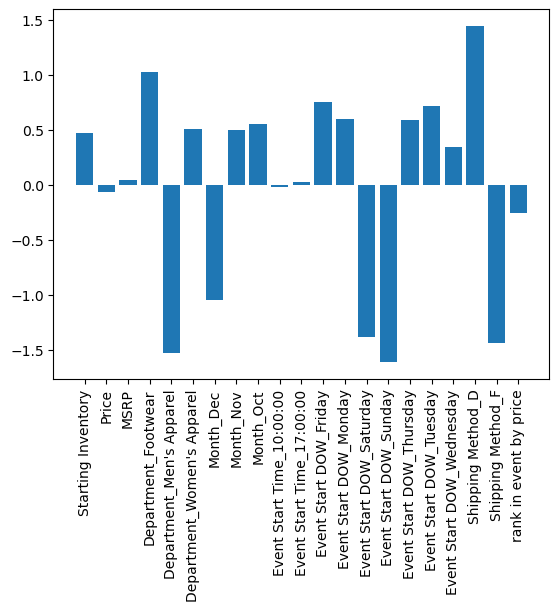

In [79]:

# define the model
model = LinearRegression()
# fit the model
model.fit(X, y)
# get importance
importance = model.coef_
# summarize feature importance
for i,v in enumerate(importance):
    print('Feature: %0d, Score: %.5f' % (i,v),X.columns[i])
# plot feature importance
#pyplot.bar([x for x in range(len(importance))], importance)
pyplot.bar(X.columns, importance)
ax1 = pyplot.subplot()
ax1.set_xticklabels(labels=X.columns,rotation=90)
pyplot.show()

### 4.1.2 LASSO feature importance
lasso (least absolute shrinkage and selection operator) is a regression analysis method that performs both variable selection and value normalisation to enhance the prediction accuracy and interpretability of the resulting statistical model.
<br>

*Source: wikipedia*

C:\Users\raymo\anaconda3\envs\DataSci\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:648: ConvergenceWarning:

Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.234e+05, tolerance: 3.242e+02



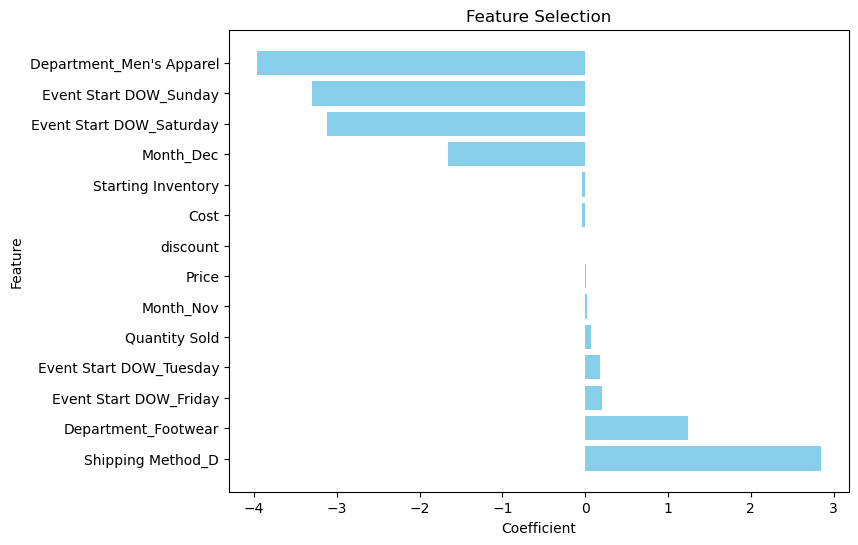

In [64]:
# Define target variable
target_variable = dummified_data['sell_through']
feature_variables = dummified_data.drop('sell_through', axis=1)

# Perform Lasso feature selection
lasso = Lasso(alpha=0.01)  # Set the alpha regularization parameter
lasso.fit(feature_variables, target_variable)

# Get the selected features and corresponding coefficients
selected_features = feature_variables.columns[lasso.coef_ != 0]
coefficients = lasso.coef_[lasso.coef_ != 0]

# Print the selected features and their coefficients
#for feature, coefficient in zip(selected_features, coefficients):
#    print(f"Feature: {feature}\tCoefficient: {coefficient}")


# Plot the feature selection visually
feature_importance = pd.DataFrame({'Feature': selected_features, 'Coefficient': coefficients})
feature_importance = feature_importance.sort_values(by='Coefficient', ascending=False)

bar_color = 'skyblue'
plt.figure(figsize=(8, 6))
plt.barh(feature_importance['Feature'], feature_importance['Coefficient'], color = bar_color)
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.title('Feature Selection')
plt.show()

## 4.2 Linear Regression

### 4.2.1 Linear regression with all factore

In [17]:


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4)
model = LinearRegression()
model.fit(X_train,y_train)
predictions = model.predict(X_test)

In [19]:

X_train_Sm= sm.add_constant(X_train)
X_train_Sm= sm.add_constant(X_train)
ls=sm.OLS(y_train,X_train_Sm).fit()
print(ls.summary())

                            OLS Regression Results                            
Dep. Variable:          Quantity Sold   R-squared:                       0.501
Model:                            OLS   Adj. R-squared:                  0.501
Method:                 Least Squares   F-statistic:                     1016.
Date:                Tue, 16 May 2023   Prob (F-statistic):               0.00
Time:                        14:36:14   Log-Likelihood:                -77424.
No. Observations:               18233   AIC:                         1.549e+05
Df Residuals:                   18214   BIC:                         1.550e+05
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

Change Data to more accureately represent data

In [22]:
X

,Style#,Event#,Starting Inventory,Cost,Price,MSRP,Department_Footwear,Department_Men's Apparel,Department_Women's Apparel,Month_Dec,...,Event Start Time_17:00:00,Event Start DOW_Friday,Event Start DOW_Monday,Event Start DOW_Saturday,Event Start DOW_Sunday,Event Start DOW_Thursday,Event Start DOW_Tuesday,Event Start DOW_Wednesday,Shipping Method_D,Shipping Method_F
0,23454,284,115,7,9.99,39,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
1,25783,304,126,7,9.99,29,1,0,0,0,...,0,0,0,0,0,1,0,0,0,1
2,2990,314,92,7,9.99,39,1,0,0,0,...,0,0,0,0,0,1,0,0,0,1
3,21412,289,115,7,9.99,27,1,0,0,0,...,0,0,0,0,0,0,0,1,0,1
4,8211,284,133,7,9.99,41,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30384,26318,974,16,1217,1524.99,1570,0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
30385,26690,504,21,1163,1534.99,1700,0,0,1,0,...,1,1,0,0,0,0,0,0,0,1
30386,17414,884,53,1159,1534.99,1805,0,0,1,1,...,0,0,0,0,0,1,0,0,0,1
30387,13748,934,16,1268,1674.99,1795,0,0,1,1,...,1,0,0,1,0,0,0,0,0,1


In [23]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4)
model = LinearRegression()
model.fit(X_train,y_train)
predictions = model.predict(X_test)
X_train_Sm= sm.add_constant(X_train)
X_train_Sm= sm.add_constant(X_train)
ls=sm.OLS(y_train,X_train_Sm).fit()
print(ls.summary())

                            OLS Regression Results                            
Dep. Variable:          Quantity Sold   R-squared:                       0.498
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     1130.
Date:                Tue, 16 May 2023   Prob (F-statistic):               0.00
Time:                        14:46:45   Log-Likelihood:                -77321.
No. Observations:               18233   AIC:                         1.547e+05
Df Residuals:                   18216   BIC:                         1.548e+05
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

### 4.2.2 Linear regression with sell through and dicount features

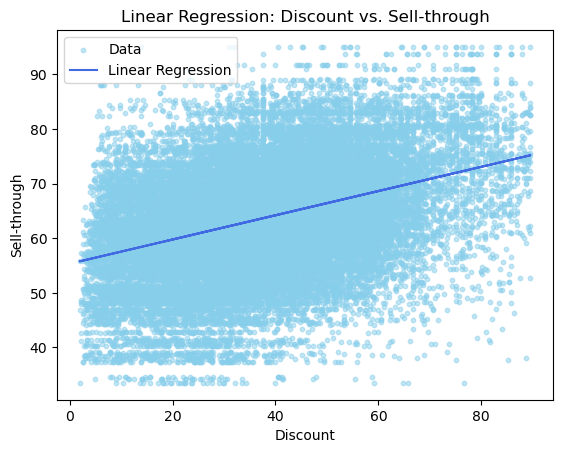

R²= 0.14363766084776297


In [65]:
# Define variables 
reg1 = f[['discount', 'sell_through']]
X = reg1[['discount']]
y = reg1['sell_through']

# Build regression
regression = LinearRegression()
regression.fit(X, y)
y_pred = regression.predict(X)
r2 = r2_score(y, y_pred)

# Plot the linear regression line and data points
plt.scatter(X, y, color='skyblue', label='Data', alpha=0.5, s=10)
plt.plot(X, y_pred, color='royalblue', label='Linear Regression')
plt.xlabel('Discount')
plt.ylabel('Sell-through')
plt.title('Linear Regression: Discount vs. Sell-through')
plt.legend()
plt.show()
print('R²=', r2)

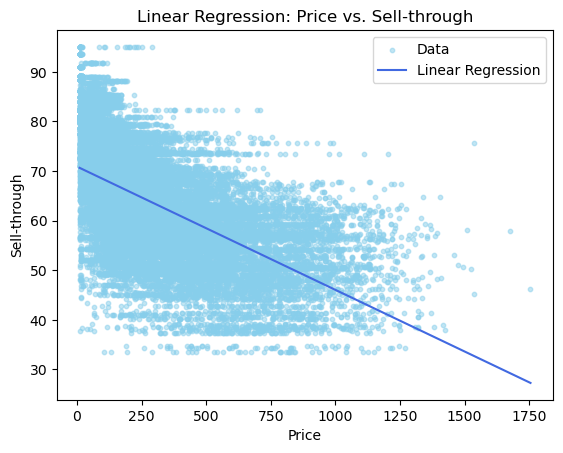

R²= 0.3548393071251127


In [66]:
# Define variables 
reg2 = f[['Price', 'sell_through']]
X = reg2[['Price']]
y = reg2['sell_through']

# Build regression
regression = LinearRegression()
regression.fit(X, y)
y_pred = regression.predict(X)
r2 = r2_score(y, y_pred)

# Plot the linear regression line and data points
plt.scatter(X, y, color='skyblue', label='Data', alpha=0.5, s=10)
plt.plot(X, y_pred, color='royalblue', label='Linear Regression')
plt.xlabel('Price')
plt.ylabel('Sell-through')
plt.title('Linear Regression: Price vs. Sell-through')
plt.legend()
plt.show()
print('R²=', r2)

## 4.3 Multi model comparison

In [88]:


# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Initialize and train the models
model1 = LogisticRegression(max_iter=10000)
model1.fit(X_train, y_train)

model2 = DecisionTreeClassifier()
model2.fit(X_train, y_train)

model3 = RandomForestClassifier()
model3.fit(X_train, y_train)

#a cluster for each product type
model4 = KMeans(n_clusters=3)
model4.fit(X_train)

model5 = LinearRegression()
model5.fit(X_train, y_train)

# Evaluate the models on the testing data
y_pred1 = model1.predict(X_test)
accuracy1 = metrics.accuracy_score(y_test, y_pred1)

y_pred2 = model2.predict(X_test)
accuracy2 = metrics.accuracy_score(y_test, y_pred2)

y_pred3 = model3.predict(X_test)
accuracy3 = metrics.accuracy_score(y_test, y_pred3)

y_pred4 = model4.predict(X_test)
# Perform evaluation specific to clustering (e.g., silhouette score)
silhouette_score = metrics.silhouette_score(X_test, y_pred4)

y_pred5 = model5.predict(X_test)
# Perform evaluation specific to regression (e.g., mean squared error)
mse = metrics.mean_squared_error(y_test, y_pred5)

# Compare the performance of the models
print("Model 1 Accuracy:", accuracy1)
print("Model 2 Accuracy:", accuracy2)
print("Model 3 Accuracy:", accuracy3)
print("Model 4 Silhouette Score:", silhouette_score)
print("Model 5 Mean Squared Error:", mse)


C:\Users\raymo\anaconda3\envs\DataSci\lib\site-packages\sklearn\linear_model\_logistic.py:444: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



Model 1 Accuracy: 0.07650542941757157
Model 2 Accuracy: 0.31663376110562685
Model 3 Accuracy: 0.19002961500493584
Model 4 Silhouette Score: 0.5606382178872444
Model 5 Mean Squared Error: 280.0645722587028


In [108]:
print("Model 1 sum:$ {:,}".format(round(sum(y_pred1),0)))
print("Model 2 sum:$ {:,}".format(round(sum(y_pred2),0)))
print("Model 3 sum:$ {:,}".format(round(sum(y_pred3),0)))
print("Model 4 sum:$ {:,}".format(round(sum(y_pred4),0)))
print("Model 5 sum:$ {:,}".format(round(sum(y_pred5),0)))

Model 1 sum:$ 293,606
Model 2 sum:$ 371,734
Model 3 sum:$ 359,785
Model 4 sum:$ 9,804
Model 5 sum:$ 370,833.0
